### 문제: PiPER의 base → link2까지 Analytical IK로 목표 pose를 만족하는 joint 각도 구하기


In [1]:
import mujoco
import numpy as np

model = mujoco.MjModel.from_xml_path("../external/mujoco_menagerie/agilex_piper/scene.xml")
data = mujoco.MjData(model)
mujoco.mj_resetData(model, data)
mujoco.mj_forward(model, data)

In [2]:
def get_local_transform(model, body_name):
    body = model.body(body_name)

    rotation_flat = np.empty(9)
    mujoco.mju_quat2Mat(rotation_flat, body.quat)

    T = np.eye(4)
    T[:3, :3] = rotation_flat.reshape(3, 3)
    T[:3, 3] = body.pos

    return T

In [3]:
T_0_1 = get_local_transform(model, "link1")
T_1_2 = get_local_transform(model, "link2")
T_2_3 = get_local_transform(model, "link3")

In [4]:
T_0_1

array([[-4.24264237e-06,  1.00000000e+00,  0.00000000e+00,
         0.00000000e+00],
       [-1.00000000e+00, -4.24264237e-06, -0.00000000e+00,
         0.00000000e+00],
       [-0.00000000e+00,  0.00000000e+00,  1.00000000e+00,
         1.23000000e-01],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         1.00000000e+00]])

In [5]:
T_1_2

array([[-4.00000000e-06, -4.00000000e-06, -1.00000000e+00,
         0.00000000e+00],
       [-1.00000000e+00,  7.99993405e-12,  4.00000000e-06,
         0.00000000e+00],
       [-8.00004507e-12,  1.00000000e+00, -4.00000000e-06,
         0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         1.00000000e+00]])

In [6]:
T_2_3

array([[ 0.99490886, -0.10077873,  0.        ,  0.28358   ],
       [ 0.10077873,  0.99490886,  0.        ,  0.028726  ],
       [ 0.        ,  0.        ,  1.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  1.        ]])

In [7]:
T_0_3 = T_0_1 @ T_1_2 @ T_2_3
T_0_3

array([[-9.94908864e-01,  1.00778726e-01,  8.24264237e-06,
        -2.83580000e-01],
       [ 8.60379287e-06,  3.14895246e-06,  1.00000000e+00,
         2.45235252e-06],
       [ 1.00778726e-01,  9.94908864e-01, -4.00000000e-06,
         1.51726000e-01],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         1.00000000e+00]])

- 위는 모두 joint 각도가 0인 reference 변환임

---


In [8]:
import sympy as sp

In [9]:
q1, q2 = sp.symbols("q1 q2", real=True)

A1 = sp.Matrix(T_0_1)
A2 = sp.Matrix(T_1_2)
A3 = sp.Matrix(T_2_3)

- q1, q2 변수를 선언하고
- 각 Transform Matrix를 SymPy 행렬로 만들고


In [10]:
A1

Matrix([
[-4.24264237419703e-6,       0.999999999991, 0.0,   0.0],
[     -0.999999999991, -4.24264237419703e-6, 0.0,   0.0],
[                 0.0,                  0.0, 1.0, 0.123],
[                 0.0,                  0.0, 0.0,   1.0]])

In [11]:
A2

Matrix([
[ -3.99999999994849e-6, -3.99999999994849e-6,      -0.999999999984, 0.0],
[      -0.999999999992, 7.99993404854149e-12,  3.99999999994849e-6, 0.0],
[-8.00004507084395e-12,       0.999999999992, -3.99999999989298e-6, 0.0],
[                  0.0,                  0.0,                  0.0, 1.0]])

In [12]:
A3

Matrix([
[0.994908864364298, -0.100778725975984, 0.0,  0.28358],
[0.100778725975984,  0.994908864364298, 0.0, 0.028726],
[              0.0,                0.0, 1.0,      0.0],
[              0.0,                0.0, 0.0,      1.0]])

In [13]:
def joint_rotation_z(theta):
    c = sp.cos(theta)
    s = sp.sin(theta)

    return sp.Matrix([
        [c, -s, 0, 0],
        [s, c, 0, 0],
        [0, 0, 1, 0],
        [0, 0, 0, 1],
    ])

- re: `piper_jacobian.ipynb`


In [14]:
T_0_3 = A1 * joint_rotation_z(q1) * A2 * joint_rotation_z(q2) * A3
p = T_0_3[:3, 3]  # position properties

- q1, q2에 대한 아래 수식으로 만들어주자


$$
\boxed{
{}^{0}T_{3}(q_1,q_2)
=
A_1
\begin{bmatrix}
\cos q_1&-\sin q_1&0&0\\
\sin q_1&\cos q_1&0&0\\
0&0&1&0\\
0&0&0&1
\end{bmatrix}
A_2
\begin{bmatrix}
\cos q_2&-\sin q_2&0&0\\
\sin q_2&\cos q_2&0&0\\
0&0&1&0\\
0&0&0&1
\end{bmatrix}
A_3
}
$$


In [15]:
p

Matrix([
[-0.028726*(-8.24264237407557e-6*sin(q1) - 0.99999999996603*cos(q1))*sin(q2) + 0.28358*(-8.24264237407557e-6*sin(q1) - 0.99999999996603*cos(q1))*cos(q2) + 0.28358*(-3.99999999987855e-6*sin(q1) + 2.4970503545039e-11*cos(q1))*sin(q2) + 0.028726*(-3.99999999987855e-6*sin(q1) + 2.4970503545039e-11*cos(q1))*cos(q2)],
[  -0.028726*(-0.99999999996603*sin(q1) + 8.24264237407557e-6*cos(q1))*sin(q2) + 0.28358*(-0.99999999996603*sin(q1) + 8.24264237407557e-6*cos(q1))*cos(q2) + 0.28358*(2.4970503545039e-11*sin(q1) + 3.99999999987855e-6*cos(q1))*sin(q2) + 0.028726*(2.4970503545039e-11*sin(q1) + 3.99999999987855e-6*cos(q1))*cos(q2)],
[                                                                                                                                                                                                                                                        0.283579999997961*sin(q2) + 0.0287259999975015*cos(q2) + 0.123]])

In [16]:
p.shape

(3, 1)

- 이렇게 $q_1$ ,$q_2$에 대한 FK 식을 구할 수 있다

$$
p(q_1,q_2)=
\begin{bmatrix}
x(q_1,q_2)\\
y(q_1,q_2)\\
z(q_1,q_2)
\end{bmatrix}
$$


In [17]:
p.subs({q1: 0.3, q2: 0.4})

Matrix([
[ -0.238842579114441],
[-0.0738799374433106],
[  0.259889651622519]])

- 각도를 대입해서 목표 위치를 만드는 FK


---

### IK


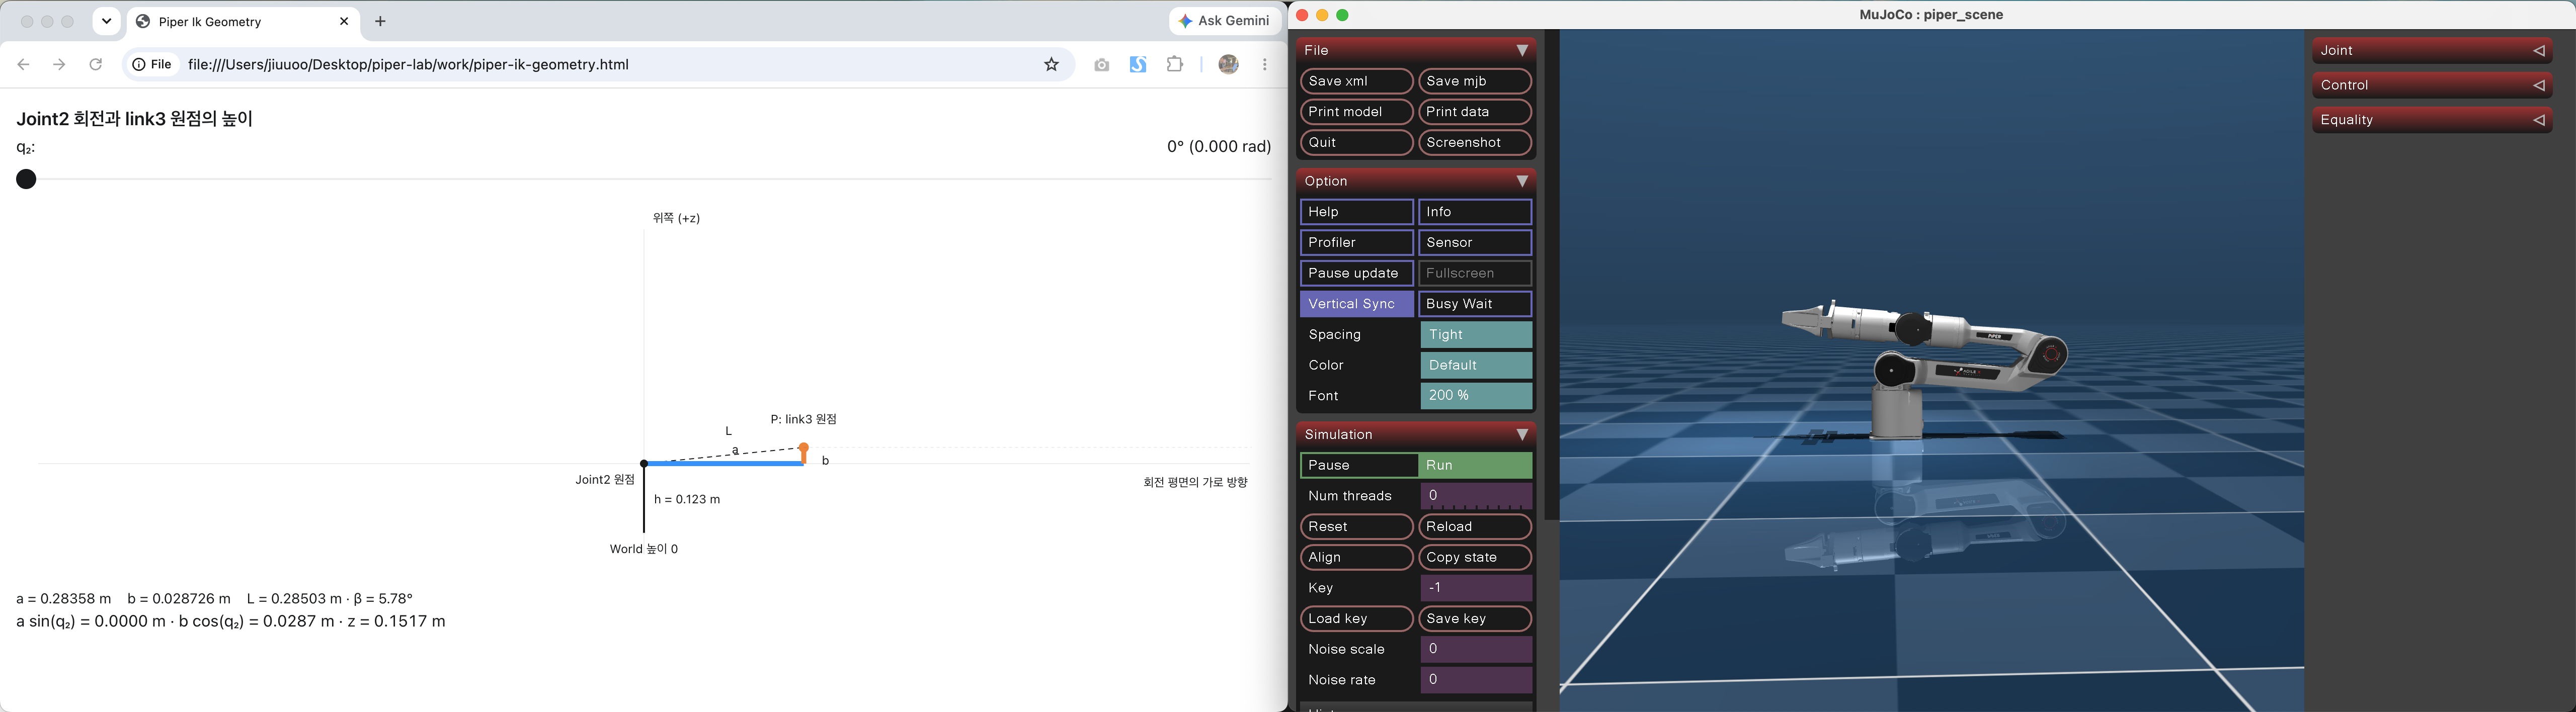


$z_d = h+L\sin(q_2+\beta)$

- $z_d$: 목표 높이

- $L$: link2의 직선거리

- $L = \sqrt{a^2+b^2}$


In [18]:
T_2_3

array([[ 0.99490886, -0.10077873,  0.        ,  0.28358   ],
       [ 0.10077873,  0.99490886,  0.        ,  0.028726  ],
       [ 0.        ,  0.        ,  1.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  1.        ]])

In [19]:
T_0_1

array([[-4.24264237e-06,  1.00000000e+00,  0.00000000e+00,
         0.00000000e+00],
       [-1.00000000e+00, -4.24264237e-06, -0.00000000e+00,
         0.00000000e+00],
       [-0.00000000e+00,  0.00000000e+00,  1.00000000e+00,
         1.23000000e-01],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         1.00000000e+00]])

In [20]:
a = T_2_3[0, 3]  # x pos
b = T_2_3[1, 3]  # y pos
h = T_0_1[2, 3]  # z pos

In [21]:
a

np.float64(0.28358)

In [22]:
b

np.float64(0.028726)

In [23]:
h

np.float64(0.123)

In [24]:
L = np.hypot(a, b)
L

np.float64(0.28503122544030157)

In [25]:
beta = np.arctan2(b, a)
beta

np.float64(0.10095333204216182)

---

① 수직 성분) 높이를 결정짓는 $q_2$부터 계산


$z_d = h+L\sin(q_2+\beta)$

$
\theta=\arcsin\left(\frac{z_d-h}{L}\right)
$

$
q_2=\theta-\beta
\quad\text{or}\quad
q_2=\pi-\theta-\beta
$

- 이처럼 $q_2$는 2가지 해가 나올 수 있음
- 실제 해는 도달 가능 조건과 joint limit으로 선택하는 원리


In [26]:
z_d = sp.symbols("z_d", real=True)

theta = sp.asin((z_d - h) / L)
theta

asin(3.5083875405414*z_d - 0.431531667486592)

In [27]:
q2_solution_1 = theta - beta
q2_solution_1

asin(3.5083875405414*z_d - 0.431531667486592) - 0.100953332042162

In [28]:
q2_solution_2 = sp.pi - theta - beta
q2_solution_2

-asin(3.5083875405414*z_d - 0.431531667486592) - 0.100953332042162 + pi

---

② 수평 성분)

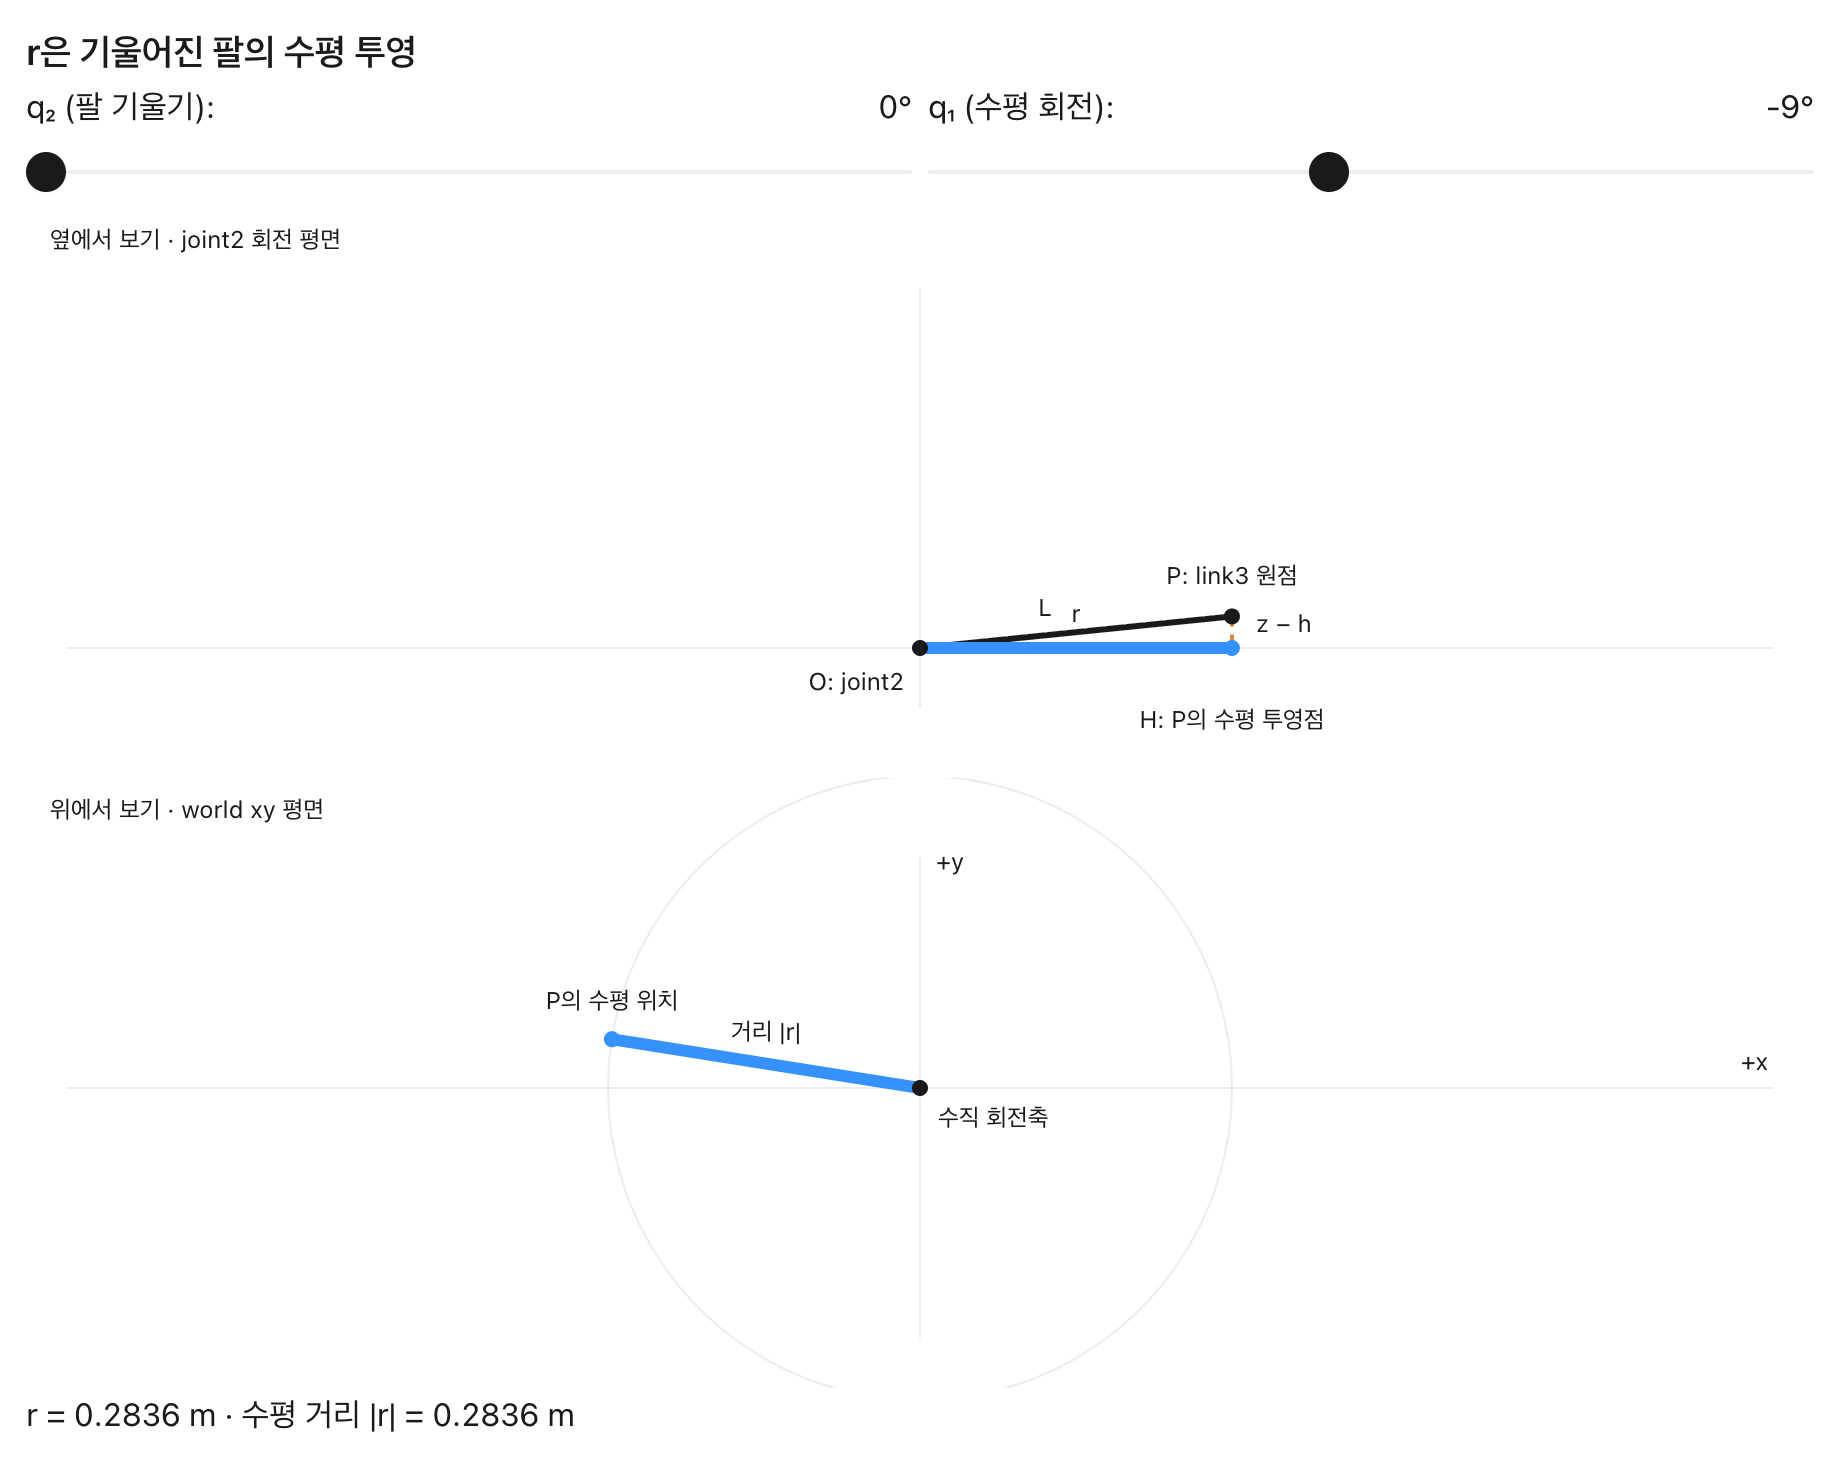
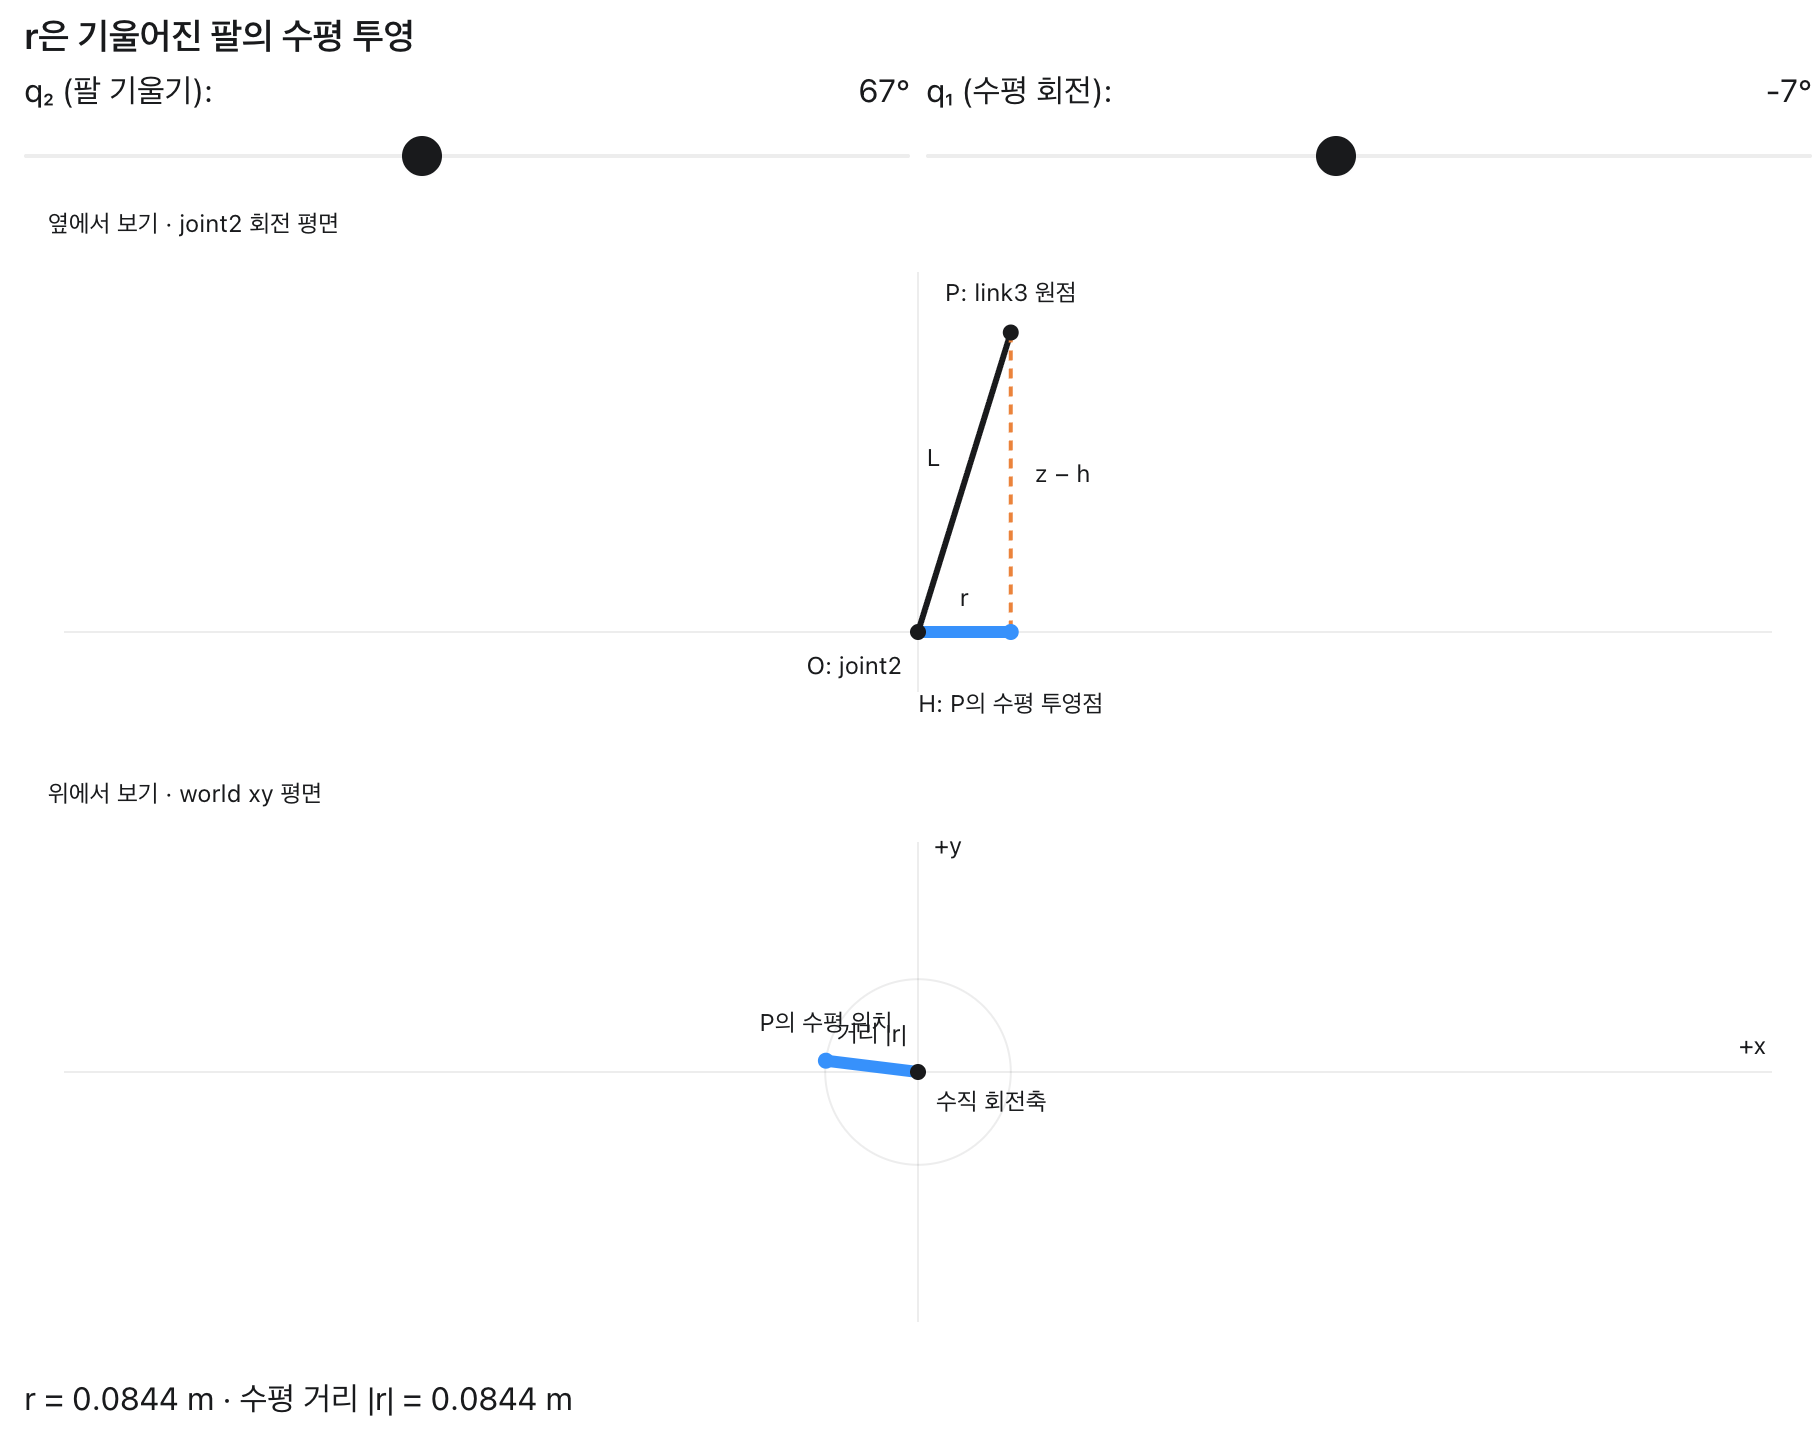


$$
x_d = -r\cos q_1 \\ \\
y_d = -r\sin q_1 \\
$$

$$
r = a\cos q_2 - b\sin q_2 \quad(q \text{ has 2 solutions}) \\
$$

$$
q_1=\operatorname{atan2}\left(-\frac{y_d}{r},-\frac{x_d}{r}\right)

\quad(r\ne0)
$$


In [29]:
x_d, y_d = sp.symbols("x_d y_d", real=True)

In [30]:
r1 = a * sp.cos(q2_solution_1) - b * sp.sin(q2_solution_1)
r2 = a * sp.cos(q2_solution_2) - b * sp.sin(q2_solution_2)

In [31]:
q1_solution_1 = sp.atan2(-y_d / r1, -x_d / r1)
q1_solution_2 = sp.atan2(-y_d / r2, -x_d / r2)

- 2개의 해를 갖고 있었으므로


In [32]:
solutions = [
    (q1_solution_1, q2_solution_1),
    (q1_solution_2, q2_solution_2),
]
solutions

[(atan2(-y_d/(-0.028726*sin(asin(3.5083875405414*z_d - 0.431531667486592) - 0.100953332042162) + 0.28358*cos(asin(3.5083875405414*z_d - 0.431531667486592) - 0.100953332042162)), -x_d/(-0.028726*sin(asin(3.5083875405414*z_d - 0.431531667486592) - 0.100953332042162) + 0.28358*cos(asin(3.5083875405414*z_d - 0.431531667486592) - 0.100953332042162))),
  asin(3.5083875405414*z_d - 0.431531667486592) - 0.100953332042162),
 (atan2(-y_d/(-0.028726*sin(asin(3.5083875405414*z_d - 0.431531667486592) + 0.100953332042162) - 0.28358*cos(asin(3.5083875405414*z_d - 0.431531667486592) + 0.100953332042162)), -x_d/(-0.028726*sin(asin(3.5083875405414*z_d - 0.431531667486592) + 0.100953332042162) - 0.28358*cos(asin(3.5083875405414*z_d - 0.431531667486592) + 0.100953332042162))),
  -asin(3.5083875405414*z_d - 0.431531667486592) - 0.100953332042162 + pi)]

---

③ 목표 xyz를 식에 대입해서 각도 확인


In [33]:
p_target = np.array(
    p.subs({q1: 0.7, q2: 1.4}), dtype=float
).reshape(3)  # possible target

p_target

array([-0.01521451, -0.0128133 ,  0.40733631])

- FK로 도달 가능한 목표 예시


In [34]:
target_values = dict(zip((x_d, y_d, z_d), p_target))
target_values

{x_d: np.float64(-0.015214508104525293),
 y_d: np.float64(-0.012813301991905422),
 z_d: np.float64(0.4073363105746461)}

- dictionary로 쌍을 지어주고


In [35]:
for q1_expr, q2_expr in solutions:
    q_candidate = np.array([
        float(q1_expr.subs(target_values)),
        float(q2_expr.subs(target_values))
    ])

    print("Joint angles [rad]:", q_candidate)

Joint angles [rad]: [0.69993458 1.4       ]
Joint angles [rad]: [-2.44165807  1.53968599]


In [36]:
q1_limits = model.joint("joint1").range
q1_limits

array([-2.618,  2.618])

In [37]:
q2_limits = model.joint("joint2").range
q2_limits

array([0.  , 3.14])

---

④ joint limit 확인


$
-2.618\le q_1\le2.618,\qquad 0\le q_2\le3.14
$

- 이게 실제 무조코에 정의된 joint limit


In [38]:
def within_joint_limits(q1, q2, q1_limits, q2_limits):
    return (
        q1_limits[0] <= q1 <= q1_limits[1]
        and q2_limits[0] <= q2 <= q2_limits[1]
    )

- joint limit 체크


In [39]:
valid_solutions = []

for q1_expr, q2_expr in solutions:
    q_candidate = np.array([
        float(q1_expr.subs(target_values)),
        float(q2_expr.subs(target_values))
    ])
    if within_joint_limits(*q_candidate, q1_limits, q2_limits):  # if within_joint_limits(q_candidate[0], q_candidate[1], range1, range2):
        valid_solutions.append(q_candidate)

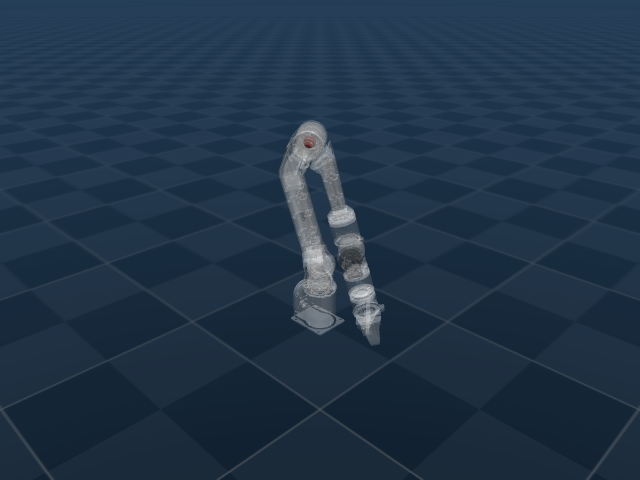

In [40]:
from IPython.display import display
from PIL import Image

# Use separate simulation data for visualization.
render_data = mujoco.MjData(model)

q_solution = valid_solutions[0]
q_indices = [
    int(model.joint("joint1").qposadr[0]),
    int(model.joint("joint2").qposadr[0]),
]

render_data.qpos[q_indices] = q_solution
mujoco.mj_forward(model, render_data)

# Configure the observer camera.
camera = mujoco.MjvCamera()
mujoco.mjv_defaultCamera(camera)
camera.lookat[:] = [0, 0, 0.2]
camera.distance = 1.2
camera.azimuth = 135
camera.elevation = -25

with mujoco.Renderer(model, height=480, width=640) as renderer:
    renderer.update_scene(render_data, camera=camera)

    # Make robot geometry transparent to reveal the target.
    for i in range(renderer.scene.ngeom):
        geom = renderer.scene.geoms[i]
        if geom.objtype == mujoco.mjtObj.mjOBJ_GEOM:
            geom.rgba[3] = 0.2

    # Add a target marker in world coordinates.
    scene = renderer.scene
    marker = scene.geoms[scene.ngeom]

    mujoco.mjv_initGeom(
        marker,
        mujoco.mjtGeom.mjGEOM_SPHERE,
        np.array([0.012, 0, 0]),
        np.asarray(p_target, dtype=float).reshape(3),
        np.eye(3).ravel(),
        np.array([1.0, 0.2, 0.2, 1.0], dtype=np.float32),
    )
    scene.ngeom += 1

    image = renderer.render().copy()

display(Image.fromarray(image))